# Finding 1: Home vs. Neutral Venue (Hannan)

Teams playing at home won about 9 percentage points more often than equally rated teams at a neutral venue. I'm using `results.csv`, and the neutral-venue games are my "no home advantage" baseline.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest

intl = pd.read_csv("data/results.csv", parse_dates=["date"]).sort_values("date", kind="stable")
intl["win"] = (intl["home_score"] > intl["away_score"]).astype(int)
intl["draw"] = (intl["home_score"] == intl["away_score"]).astype(int)
intl["home_venue"] = (~intl["neutral"]).astype(int)
intl["competitive"] = (intl["tournament"] != "Friendly").astype(int)
intl["year"] = intl["date"].dt.year

print("Shape:", intl.shape, "| Missing values:", intl.isna().sum().sum())
print(intl["home_venue"].value_counts())

Shape: (49547, 14) | Missing values: 0
home_venue
1    36389
0    13158
Name: count, dtype: int64


In [3]:
home = intl[intl["home_venue"] == 1]
neutral = intl[intl["home_venue"] == 0]
z, p = proportions_ztest([home["win"].sum(), neutral["win"].sum()], [len(home), len(neutral)])

print(f"Home: {100 * home['win'].mean():.1f}%  Neutral: {100 * neutral['win'].mean():.1f}%  z = {z:.1f}, p = {p:.1e}")

Home: 50.7%  Neutral: 44.2%  z = 12.9, p = 2.7e-38


That's a 6.5 point gap, but the teams in each group might not be equally good. The dataset has no rankings, so I built a simple Elo rating from past results (with no home bonus) and only kept matches where both teams had played at least 20 games.

In [4]:
def add_elo(df, k=30):
    ratings, played, elo_diff, min_played = {}, {}, [], []
    for row in df.itertuples():
        r_home, r_away = ratings.get(row.home_team, 1500), ratings.get(row.away_team, 1500)
        elo_diff.append(r_home - r_away)
        min_played.append(min(played.get(row.home_team, 0), played.get(row.away_team, 0)))

        expected = 1 / (1 + 10 ** ((r_away - r_home) / 400))
        actual = 1 if row.win else (0.5 if row.draw else 0)
        ratings[row.home_team] = r_home + k * (actual - expected)
        ratings[row.away_team] = r_away - k * (actual - expected)
        for team in (row.home_team, row.away_team):
            played[team] = played.get(team, 0) + 1
    return df.assign(elo_diff=elo_diff, min_played=min_played)

df = add_elo(intl)
df = df[df["min_played"] >= 20].copy()

model = smf.logit("win ~ home_venue + I(elo_diff / 100)", data=df).fit(disp=0)
effect = model.get_margeff().summary_frame().loc["home_venue"]

print("Matches kept:", len(df))
print(f"Effect of home venue: +{100 * effect['dy/dx']:.1f} points "
      f"(95% CI {100 * effect['Conf. Int. Low']:.1f} to {100 * effect['Cont. Int. Hi.']:.1f})")

Matches kept: 45205
Effect of home venue: +9.0 points (95% CI 8.0 to 9.9)


After controlling for strength, playing at home is worth about +9 points of win rate.

**Check 1:** To make sure this isn't Simpson's paradox, I split matches into strength bands and compared home vs. neutral inside each one.

In [5]:
labels = ["≤ -200", "-200 to -100", "-100 to -50", "-50 to 0", "0 to 50", "50 to 100", "100 to 200", "> 200"]
df["elo_band"] = pd.cut(df["elo_diff"], [-np.inf, -200, -100, -50, 0, 50, 100, 200, np.inf], labels=labels)

table = 100 * df.pivot_table(index="elo_band", columns="home_venue", values="win", observed=True)
table.columns = ["Neutral", "Home"]
table["Gap"] = table["Home"] - table["Neutral"]
table.round(1)

,Neutral,Home,Gap
elo_band,,,
≤ -200,7.7,13.9,6.2
-200 to -100,18.7,29.3,10.6
-100 to -50,28.1,38.4,10.3
-50 to 0,35.8,45.7,9.9
0 to 50,42.4,53.5,11.1
50 to 100,50.1,60.7,10.6
100 to 200,61.0,69.5,8.5
> 200,78.0,85.1,7.2


Home teams win more in all 8 bands.

**Check 2:** Does the effect change for competitive matches or over time?

In [6]:
m_type = smf.logit("win ~ home_venue * competitive + I(elo_diff / 100)", data=df).fit(disp=0)
m_time = smf.logit("win ~ home_venue * year + I(elo_diff / 100)", data=df).fit(disp=0)

print(f"Home x competitive: p = {m_type.pvalues['home_venue:competitive']:.2f}")
print(f"Home x year: p = {m_time.pvalues['home_venue:year']:.2f}")

Home x competitive: p = 0.23
Home x year: p = 0.24


Neither is significant, so I didn't find evidence that it changes (but a small change could still be hiding in there).

My EDA plot of the raw trend over time made home advantage look like it was growing, but that went away after controlling for Elo.

This shows home teams win more, not *why*. There's no attendance or travel data.

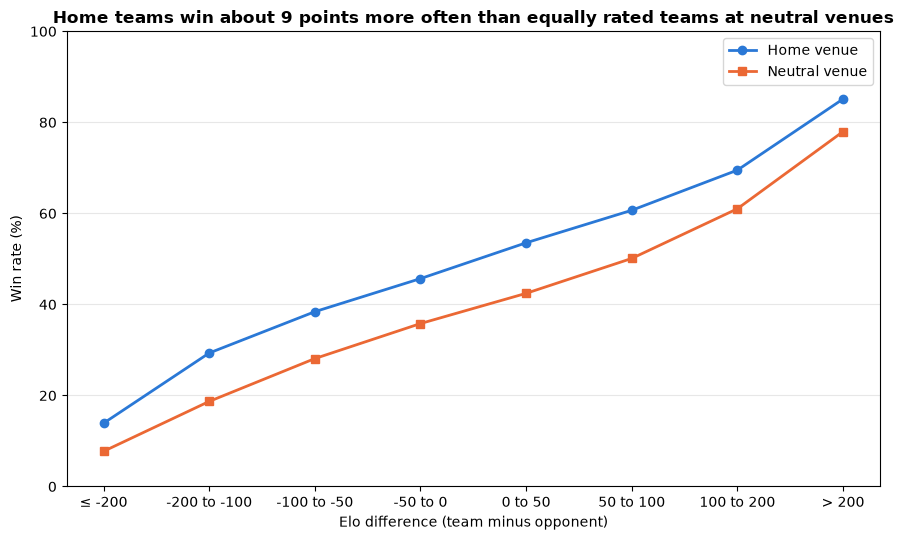

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(labels, table["Home"], marker="o", color="#2a78d6", linewidth=2, label="Home venue")
ax.plot(labels, table["Neutral"], marker="s", color="#eb6834", linewidth=2, label="Neutral venue")

ax.set_title("Home teams win about 9 points more often than equally rated teams at neutral venues",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Elo difference (team minus opponent)")
ax.set_ylabel("Win rate (%)")
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/finding-one.png", dpi=200, bbox_inches="tight")
plt.show()